# 🪄 SpellEngine — Dual-Task ASR + SER (Kaggle Edition)

A production-grade Kaggle notebook for a speech-driven spell-casting game.

| Model | Architecture | Role |
|-------|--------------|------|
| **A** | Conformer Encoder (from scratch) + CTC head + Attention-Pooling SER head | Lightweight inference baseline |
| **B** | Whisper-Small + LoRA (PEFT) + classification head | High-accuracy reference |

**Training tricks**: Kendall Uncertainty Weighting · OneCycleLR · AMP (mixed precision) · SpecAugment · Audiomentations (reverb / noise) · strict checkpointing under `/kaggle/working/` with `resume_from_checkpoint`.

---

## 🛠 Setup before running

1. **Settings → Accelerator → GPU T4 x2** (or P100). CPU-only will work but will be slow.
2. **Settings → Internet → On** (needed to download Whisper-Small weights).
3. **Add Input Datasets** (right sidebar → "+ Add Input"):
   - Search & add: **`crema-d`** (CREMA-D emotional speech corpus).
4. Click **Save Version** at any point — `/kaggle/working/` artefacts are preserved between sessions.

> **Spell Power formula** = `intent_weight × emotion_confidence × clarity(1 − WER)`. Anger/joy + clear diction ⇒ stronger spell.


In [1]:
!pip install -q --no-deps \
    rapidfuzz \
    accelerate \
    safetensors \
    huggingface-hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 49.6 MB/s eta 0:00:00a 0:00:01


## CELL 1 — Environment Setup

Kaggle's base image already has `torch`, `torchaudio`, `transformers`, `librosa`, `evaluate` installed — we only `pip install` the deltas (`peft`, `audiomentations`, `jiwer`, ONNX tooling). Everything writes under `/kaggle/working/` which is persisted with the notebook version.

In [2]:
# ============================================================================
# CELL 1 — Environment Setup (Kaggle, NumPy-ABI-safe, restart-aware)
# ============================================================================

# ---- 1.1 Install missing dependencies (one-time) ----
import os, sys, subprocess

INSTALL_FLAG = "/kaggle/working/.deps_installed"

if not os.path.exists(INSTALL_FLAG):
    print("Installing dependencies (one-time, ~60s)…")
    # Pin numpy first to avoid ABI drift with Kaggle's pre-built wheels
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy==1.26.4", "--force-reinstall", "--no-deps"], check=True)
    # Install our deps without letting them pull a different numpy
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "peft>=0.10.0",
                    "audiomentations==0.35.0",
                    "jiwer==3.0.4",
                    "onnx==1.16.1",
                    "onnxruntime==1.18.1",
                    "onnxscript<0.2"], check=True)
    open(INSTALL_FLAG, "w").close()
    print("\n" + "="*60)
    print("⚠ DEPENDENCIES INSTALLED — RESTART REQUIRED")
    print("="*60)
    print("Click:  Run → Restart Session")
    print("Then re-run this cell — it will skip install and continue.")
    print("="*60)
    raise SystemExit("Restart kernel now.")

print("✓ dependencies already installed, continuing")

# ---- 1.2 Standard imports ----
import json, time, math, random, gc, re, shutil, warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch

# ---- 1.3 Project directory layout (Kaggle-native paths) ----
WORKING = "/kaggle/working"
INPUT   = "/kaggle/input"

PROJECT_ROOT = f"{WORKING}/SpellEngine"
DIRS = {
    "root":        PROJECT_ROOT,
    "manifests":   f"{PROJECT_ROOT}/manifests",
    "ckpts":       f"{PROJECT_ROOT}/checkpoints",
    "ckpts_conf":  f"{PROJECT_ROOT}/checkpoints/conformer",
    "ckpts_whis":  f"{PROJECT_ROOT}/checkpoints/whisper_lora",
    "exports":     f"{PROJECT_ROOT}/exports",
    "logs":        f"{PROJECT_ROOT}/logs",
    "cache":       f"{PROJECT_ROOT}/hf_cache",
}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

# Route HuggingFace cache into /kaggle/working so model weights survive a re-run
os.environ["HF_HOME"]            = DIRS["cache"]
os.environ["TRANSFORMERS_CACHE"] = DIRS["cache"]
os.environ["HF_DATASETS_CACHE"]  = DIRS["cache"]

# ---- 1.4 Reproducibility ----
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---- 1.5 Device + capability check ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print(f"PyTorch         : {torch.__version__}")
print(f"NumPy           : {np.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"GPU {i}           : {p.name}  ({p.total_memory/1e9:.1f} GB)")
print(f"Mixed precision : {USE_AMP}")
print(f"Project root    : {PROJECT_ROOT}")
print(f"Inputs visible  : {os.listdir(INPUT) if os.path.isdir(INPUT) else 'NONE'}")

✓ dependencies already installed, continuing
PyTorch         : 2.10.0+cu128
NumPy           : 1.26.4
CUDA available  : True
GPU 0           : Tesla T4  (15.6 GB)
GPU 1           : Tesla T4  (15.6 GB)
Mixed precision : True
Project root    : /kaggle/working/SpellEngine
Inputs visible  : ['datasets']


## CELL 2 — Data Discovery & Manifest Building

Kaggle datasets live under `/kaggle/input/<dataset-slug>/`. **No downloads happen here** — the datasets you added in the sidebar are already mounted. This cell auto-discovers them by content shape (looking for `*.trans.txt` for LibriSpeech and the `XXXX_XXX_XXX_XX.wav` filename pattern for CREMA-D), so it works regardless of which specific Kaggle mirror you picked.

If a dataset isn't found, the cell will tell you exactly what to add.

In [3]:
# ---- CELL 2 (CREMA-D only, self-contained) ----
import os, re
import pandas as pd
from pathlib import Path

# Defensive: re-define what later cells need, in case kernel was restarted
SEED = 1337
WORKING = "/kaggle/working"
PROJECT_ROOT = f"{WORKING}/SpellEngine"
DIRS = {
    "manifests":  f"{PROJECT_ROOT}/manifests",
    "ckpts_conf": f"{PROJECT_ROOT}/checkpoints/conformer",
    "ckpts_whis": f"{PROJECT_ROOT}/checkpoints/whisper_lora",
    "exports":    f"{PROJECT_ROOT}/exports",
    "logs":       f"{PROJECT_ROOT}/logs",
    "cache":      f"{PROJECT_ROOT}/hf_cache",
}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

INPUT_DIR = Path("/kaggle/input")

# ----- Find CREMA-D -----
def find_crema_root():
    for d in INPUT_DIR.rglob("AudioWAV"):
        if d.is_dir() and any(d.glob("*.wav")):
            return d
    return None

crema_root = find_crema_root()
print(f"CREMA-D root: {crema_root}")
assert crema_root is not None, "CREMA-D not found! Check the Input panel."

# ----- Build CREMA-D manifest with BOTH tasks -----
EMO = {"NEU":"neutral","HAP":"happy","SAD":"sad","ANG":"anger","FEA":"fear","DIS":"disgust"}
SENT = {
    "IEO":"it's eleven o'clock", "TIE":"that is exactly what happened",
    "IOM":"i'm on my way to the meeting", "IWW":"i wonder what this is about",
    "TAI":"the airplane is almost full", "MTI":"maybe tomorrow it will be cold",
    "IWL":"i would like a new alarm clock", "ITH":"i think i have a doctor's appointment",
    "DFA":"don't forget a jacket", "ITS":"i think i've seen this before",
    "TSI":"the surface is slick", "WSI":"we'll stop in a couple of minutes",
}

rows = []
for wav in crema_root.glob("*.wav"):
    parts = wav.stem.split("_")
    if len(parts) != 4:
        continue
    _, sent_code, emo_code, _ = parts
    text = SENT.get(sent_code, "")
    emotion = EMO.get(emo_code, "neutral")
    if not text:
        continue
    # CRITICAL: CREMA-D has known transcripts AND emotion labels —
    # so each clip can serve as BOTH an ASR and an SER training example.
    rows.append({"path": str(wav), "text": text, "emotion": emotion, "task": "asr"})
    rows.append({"path": str(wav), "text": text, "emotion": emotion, "task": "ser"})

crema_df = pd.DataFrame(rows)
print(f"Built {len(crema_df):,} (clip, task) rows from CREMA-D")

# Deterministic train/dev/test split — split by FILE so the same clip never spans splits
unique_files = pd.Series(crema_df["path"].unique()).sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(unique_files)
train_files = set(unique_files[:int(0.8*n)])
dev_files   = set(unique_files[int(0.8*n):int(0.9*n)])
test_files  = set(unique_files[int(0.9*n):])

def assign_split(p):
    if p in train_files: return "train"
    if p in dev_files:   return "dev"
    return "test"

crema_df["split"] = crema_df["path"].map(assign_split)

manifest = crema_df.copy()
manifest_path = Path(DIRS["manifests"]) / "spell_engine_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print(f"\nTotal rows: {len(manifest):,}")
print(manifest.groupby(['task','split']).size().unstack(fill_value=0))
print(f"\nManifest saved → {manifest_path}")

assert len(manifest) > 0, "Empty manifest!"



CREMA-D root: /kaggle/input/datasets/ejlok1/cremad/AudioWAV
Built 14,884 (clip, task) rows from CREMA-D

Total rows: 14,884
split  dev  test  train
task                   
asr    744   745   5953
ser    744   745   5953

Manifest saved → /kaggle/working/SpellEngine/manifests/spell_engine_manifest.csv


## CELL 3 — Data Pipeline (Lazy Loading, SpecAugment, Audiomentations)

A truly **lazy** `Dataset`: each `__getitem__` reads exactly one audio file from `/kaggle/input/`, applies augmentation, and returns features + labels. Nothing held in RAM — that's how a 35 GB corpus stays tractable on Kaggle's 16 GB host RAM.

Waveform-level augmentations (noise, room IR, pitch, gain) simulate a player's bedroom acoustics. SpecAugment then masks bands of the Mel spectrogram for ASR robustness.

In [4]:
# ============================================================================
# CELL 3 — Data Pipeline (Lazy Loading, SpecAugment, Audiomentations)
# ============================================================================
import torch, torchaudio, numpy as np, pandas as pd
from torch.utils.data import Dataset, DataLoader
from audiomentations import Compose, AddGaussianNoise, PitchShift, Gain
import string, warnings, logging

# Silence any leftover audiomentations / pyroomacoustics chatter
warnings.filterwarnings("ignore")
logging.getLogger("audiomentations").setLevel(logging.ERROR)

SR = 16000
N_MELS = 80
N_FFT = 400
HOP = 160

EMOTIONS = ["neutral", "happy", "sad", "anger", "fear", "disgust"]
EMO2IDX  = {e:i for i,e in enumerate(EMOTIONS)}
IDX2EMO  = {i:e for e,i in EMO2IDX.items()}

# ----- 3.1 Char tokenizer for the Conformer CTC head -----
class CharTokenizer:
    def __init__(self):
        self.blank = 0
        chars = list(" '") + list(string.ascii_lowercase)
        self.itos = ["<blank>"] + chars
        self.stoi = {c: i for i, c in enumerate(self.itos)}
    @property
    def vocab_size(self): return len(self.itos)
    def encode(self, text: str):
        text = text.lower()
        return [self.stoi[c] for c in text if c in self.stoi]
    def decode(self, ids, collapse=True):
        out, prev = [], None
        for i in ids:
            if collapse and i == prev: continue
            prev = i
            if i == self.blank: continue
            out.append(self.itos[i])
        return "".join(out)

tokenizer = CharTokenizer()
print(f"Char vocab size: {tokenizer.vocab_size}")

# ----- 3.2 Audio augmentation chain (no RoomSimulator — needs pyroomacoustics) -----
wave_aug = Compose([
    AddGaussianNoise(min_amplitude=0.001, max_amplitude=0.01, p=0.4),
    Gain(min_gain_db=-6, max_gain_db=6, p=0.5),
    PitchShift(min_semitones=-2, max_semitones=2, p=0.3),
])

def spec_augment(mel: torch.Tensor, F=27, T=40, num_F=2, num_T=2):
    """In-place SpecAugment on (n_mels, frames)."""
    mel = mel.clone()
    n_mels, n_frames = mel.shape
    for _ in range(num_F):
        f = np.random.randint(0, F+1); f0 = np.random.randint(0, max(1, n_mels - f))
        mel[f0:f0+f, :] = 0
    for _ in range(num_T):
        t = np.random.randint(0, T+1); t0 = np.random.randint(0, max(1, n_frames - t))
        mel[:, t0:t0+t] = 0
    return mel

# ----- 3.3 The Dataset -----
class SpellEngineDataset(Dataset):
    def __init__(self, manifest_df: pd.DataFrame, split: str,
                 augment: bool = False, max_seconds: float = 16.0,
                 use_whisper_features: bool = False, whisper_extractor=None):
        self.df = manifest_df[manifest_df["split"] == split].reset_index(drop=True)
        self.augment = augment
        self.max_samples = int(max_seconds * SR)
        self.use_whisper_features = use_whisper_features
        self.whisper_extractor = whisper_extractor
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, power=2.0)
        self.db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80)

    def __len__(self): return len(self.df)

    def _load_audio(self, path):
        try:
            wav, sr = torchaudio.load(path)
        except Exception:
            import soundfile as sf
            data, sr = sf.read(path)
            wav = torch.from_numpy(data.astype(np.float32))
            if wav.dim() == 1: wav = wav.unsqueeze(0)
        if wav.shape[0] > 1: wav = wav.mean(dim=0, keepdim=True)
        if sr != SR: wav = torchaudio.functional.resample(wav, sr, SR)
        wav = wav.squeeze(0)
        if wav.numel() > self.max_samples:
            start = np.random.randint(0, wav.numel() - self.max_samples) if self.augment else 0
            wav = wav[start:start + self.max_samples]
        return wav

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        wav = self._load_audio(row["path"])
        if self.augment:
            try:
                wav_np = wave_aug(samples=wav.numpy(), sample_rate=SR)
                wav = torch.from_numpy(wav_np)
            except Exception:
                pass

        if self.use_whisper_features:
            feats = self.whisper_extractor(
                wav.numpy(), sampling_rate=SR, return_tensors="pt"
            ).input_features.squeeze(0)
        else:
            mel = self.mel(wav)
            mel = self.db(mel + 1e-9)
            mel = (mel - mel.mean()) / (mel.std() + 1e-5)
            if self.augment: mel = spec_augment(mel)
            feats = mel

        text_ids = torch.tensor(tokenizer.encode(str(row["text"])), dtype=torch.long)
        emo_id   = torch.tensor(EMO2IDX[row["emotion"]], dtype=torch.long)

        return {
            "features": feats, "feat_len": feats.shape[-1],
            "text_ids": text_ids, "text_len": len(text_ids),
            "emotion":  emo_id,  "task": row["task"],
        }

# ----- 3.4 Collate (pads variable-length) -----
def collate_conformer(batch):
    max_T = max(b["feat_len"] for b in batch)
    max_L = max(max(b["text_len"] for b in batch), 1)
    n_mels = batch[0]["features"].shape[0]
    feats = torch.zeros(len(batch), n_mels, max_T)
    feat_lens = torch.zeros(len(batch), dtype=torch.long)
    texts = torch.zeros(len(batch), max_L, dtype=torch.long)
    text_lens = torch.zeros(len(batch), dtype=torch.long)
    emotions  = torch.zeros(len(batch), dtype=torch.long)
    tasks = []
    for i, b in enumerate(batch):
        T = b["feat_len"]
        feats[i, :, :T] = b["features"]
        feat_lens[i] = T
        L = b["text_len"]
        if L > 0: texts[i, :L] = b["text_ids"]
        text_lens[i] = L
        emotions[i]  = b["emotion"]
        tasks.append(b["task"])
    return {"features":feats, "feat_lens":feat_lens, "texts":texts,
            "text_lens":text_lens, "emotions":emotions, "tasks":tasks}

def collate_whisper(batch):
    feats = torch.stack([b["features"] for b in batch])
    max_L = max(max(b["text_len"] for b in batch), 1)
    texts = torch.zeros(len(batch), max_L, dtype=torch.long)
    text_lens = torch.zeros(len(batch), dtype=torch.long)
    emotions  = torch.zeros(len(batch), dtype=torch.long)
    tasks = []
    for i, b in enumerate(batch):
        L = b["text_len"]
        if L > 0: texts[i, :L] = b["text_ids"]
        text_lens[i] = L
        emotions[i]  = b["emotion"]
        tasks.append(b["task"])
    return {"features":feats, "feat_lens":None, "texts":texts,
            "text_lens":text_lens, "emotions":emotions, "tasks":tasks}

manifest = pd.read_csv(Path(DIRS["manifests"]) / "spell_engine_manifest.csv")
print(f"Manifest rows: {len(manifest):,}")
print(manifest.groupby(['task','split']).size().unstack(fill_value=0))

# Smoke-test one item
_ds = SpellEngineDataset(manifest, "train", augment=False)
_item = _ds[0]
print(f"\n✓ first item: feats={tuple(_item['features'].shape)}, text_len={_item['text_len']}, task={_item['task']}")

Char vocab size: 29
Manifest rows: 14,884
split  dev  test  train
task                   
asr    744   745   5953
ser    744   745   5953

✓ first item: feats=(80, 244), text_len=20, task=asr


## CELL 4 — Visual EDA

Sanity check before training: waveform & log-Mel for one ASR + one SER sample, emotion class balance, transcript-length histogram. Catch corpus pathologies (extreme imbalance, silent files) now rather than after a 6-hour run.

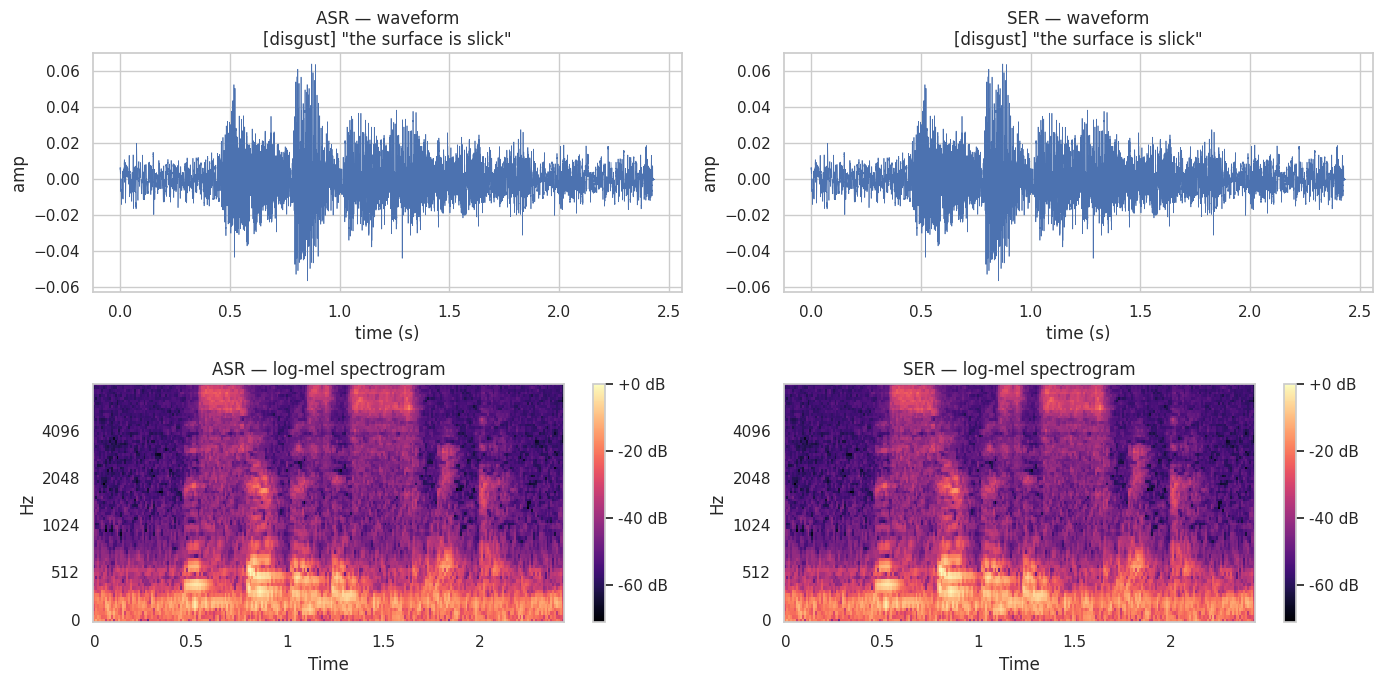

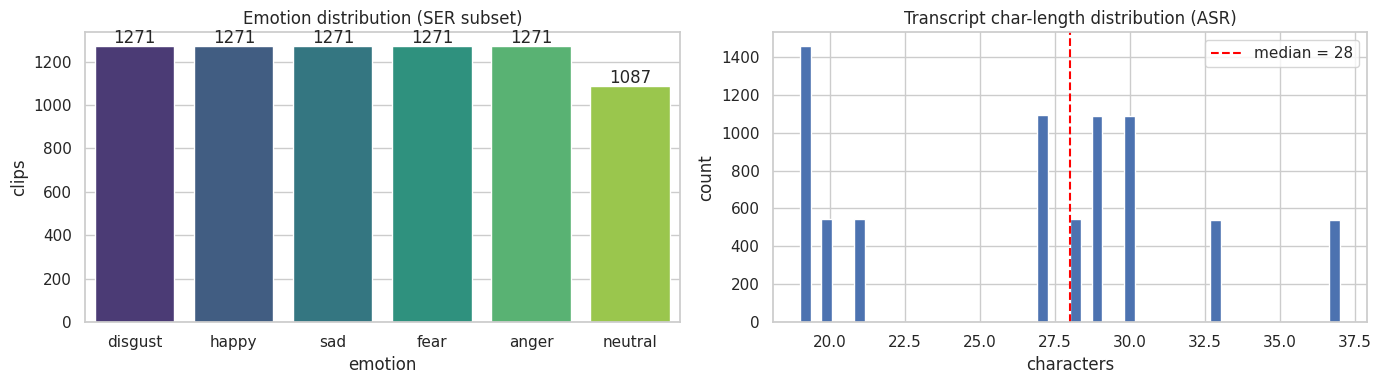

ASR clips      : 7,442
SER clips      : 7,442
Median transcript chars: 28 | max: 37


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display

sns.set_theme(style="whitegrid")

# 4.1 Waveform vs Mel-spectrogram, one sample per task
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for col, task in enumerate(["asr", "ser"]):
    sub = manifest[manifest["task"] == task]
    if len(sub) == 0:
        for r in range(2): axes[r, col].set_visible(False)
        continue
    sample = sub.iloc[0]
    wav, sr = torchaudio.load(sample["path"])
    wav = wav.mean(0).numpy()
    if sr != SR: wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)

    axes[0, col].plot(np.arange(len(wav))/SR, wav, lw=0.5)
    axes[0, col].set_title(f"{task.upper()} — waveform\n[{sample['emotion']}] \"{str(sample['text'])[:60]}\"")
    axes[0, col].set_xlabel("time (s)"); axes[0, col].set_ylabel("amp")

    mel = librosa.feature.melspectrogram(y=wav, sr=SR, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=axes[1, col])
    axes[1, col].set_title(f"{task.upper()} — log-mel spectrogram")
    fig.colorbar(img, ax=axes[1, col], format="%+2.f dB")
plt.tight_layout(); plt.show()

# 4.2 Emotion distribution + transcript-length histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ser_sub = manifest[manifest["task"]=="ser"]
if len(ser_sub) > 0:
    emo_counts = ser_sub["emotion"].value_counts()
    sns.barplot(x=emo_counts.index, y=emo_counts.values, ax=axes[0], palette="viridis")
    axes[0].set_title("Emotion distribution (SER subset)"); axes[0].set_ylabel("clips")
    for i, v in enumerate(emo_counts.values):
        axes[0].text(i, v + max(emo_counts.values)*0.01, str(v), ha="center")
else:
    axes[0].set_visible(False)

text_lens = manifest[manifest["task"]=="asr"]["text"].fillna("").astype(str).str.len()
if len(text_lens) > 0:
    axes[1].hist(text_lens, bins=50, color="#4c72b0", edgecolor="white")
    axes[1].set_title("Transcript char-length distribution (ASR)")
    axes[1].set_xlabel("characters"); axes[1].set_ylabel("count")
    axes[1].axvline(text_lens.median(), color="red", ls="--", label=f"median = {text_lens.median():.0f}")
    axes[1].legend()
else:
    axes[1].set_visible(False)
plt.tight_layout(); plt.show()

print(f"ASR clips      : {(manifest['task']=='asr').sum():,}")
print(f"SER clips      : {(manifest['task']=='ser').sum():,}")
if len(text_lens) > 0:
    print(f"Median transcript chars: {text_lens.median():.0f} | max: {text_lens.max()}")


## CELL 5 — Model A: Conformer from Scratch

Clean PyTorch Conformer encoder.

**Per-block flow**: ½ feed-forward → multi-head self-attention → depthwise-separable convolution → ½ feed-forward → LayerNorm. Every sub-module wraps a residual connection — what makes Conformer train without the warmup pain of vanilla Transformers on speech.

**Dim check**: `d_model=144`, `n_heads=4` ⇒ `d_head = 144/4 = 36` ✓. Conv module's `expansion=2` projects 144 → 288 → GLU → 144, preserving the residual shape.

In [6]:
import torch, torch.nn as nn, torch.nn.functional as F

class Swish(nn.Module):
    def forward(self, x): return x * torch.sigmoid(x)

class FeedForwardModule(nn.Module):
    def __init__(self, d_model, expansion=4, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model*expansion), Swish(), nn.Dropout(dropout),
            nn.Linear(d_model*expansion, d_model), nn.Dropout(dropout),
        )
    def forward(self, x): return self.net(x)

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0, f"d_model={d_model} not divisible by heads={num_heads}"
        self.norm = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        x_n = self.norm(x)
        out, _ = self.attn(x_n, x_n, x_n, key_padding_mask=mask, need_weights=False)
        return self.drop(out)

class ConformerConvModule(nn.Module):
    def __init__(self, d_model, kernel_size=31, expansion=2, dropout=0.1):
        super().__init__()
        assert kernel_size % 2 == 1
        inner = d_model * expansion
        self.norm = nn.LayerNorm(d_model)
        self.pw1 = nn.Conv1d(d_model, inner*2, 1)
        self.dw  = nn.Conv1d(inner, inner, kernel_size, padding=kernel_size//2, groups=inner)
        self.bn  = nn.BatchNorm1d(inner)
        self.act = Swish()
        self.pw2 = nn.Conv1d(inner, d_model, 1)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        x = self.norm(x).transpose(1, 2)
        x = F.glu(self.pw1(x), dim=1)
        x = self.act(self.bn(self.dw(x)))
        x = self.pw2(x)
        return self.drop(x.transpose(1, 2))

class ConformerBlock(nn.Module):
    def __init__(self, d_model=144, num_heads=4, ff_expansion=4, conv_kernel=31, dropout=0.1):
        super().__init__()
        self.ff1  = FeedForwardModule(d_model, ff_expansion, dropout)
        self.mhsa = MultiHeadSelfAttention(d_model, num_heads, dropout)
        self.conv = ConformerConvModule(d_model, conv_kernel, dropout=dropout)
        self.ff2  = FeedForwardModule(d_model, ff_expansion, dropout)
        self.norm = nn.LayerNorm(d_model)
    def forward(self, x, mask=None):
        x = x + 0.5 * self.ff1(x)
        x = x + self.mhsa(x, mask=mask)
        x = x + self.conv(x)
        x = x + 0.5 * self.ff2(x)
        return self.norm(x)

class ConvSubsampler(nn.Module):
    """4× temporal subsampling — turns ~10 ms frames into ~40 ms."""
    def __init__(self, in_channels, d_model):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, d_model, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(d_model, d_model, 3, stride=2, padding=1), nn.ReLU(),
        )
        self.proj = nn.Linear(d_model * (((in_channels+1)//2 + 1)//2), d_model)
    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.net(x)
        b, c, f, t = x.shape
        x = x.permute(0, 3, 1, 2).reshape(b, t, c*f)
        return self.proj(x)

class AttentionPool(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.score = nn.Linear(d_model, 1)
    def forward(self, x, mask=None):
        s = self.score(x).squeeze(-1)
        if mask is not None: s = s.masked_fill(mask, -1e4)
        w = F.softmax(s, dim=-1).unsqueeze(-1)
        return (x * w).sum(dim=1)

class ConformerSpellEngine(nn.Module):
    def __init__(self, n_mels=80, d_model=144, num_layers=8, num_heads=4,
                 conv_kernel=31, dropout=0.1, vocab_size=29, num_emotions=6):
        super().__init__()
        self.subsample = ConvSubsampler(n_mels, d_model)
        self.dropout   = nn.Dropout(dropout)
        self.layers    = nn.ModuleList([
            ConformerBlock(d_model, num_heads, 4, conv_kernel, dropout)
            for _ in range(num_layers)])
        self.ctc_head  = nn.Linear(d_model, vocab_size)
        self.emo_pool  = AttentionPool(d_model)
        self.emo_head  = nn.Sequential(
            nn.Linear(d_model, d_model), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model, num_emotions))

    @staticmethod
    def _len_after_subsample(L): return ((L + 1) // 2 + 1) // 2

    def _make_mask(self, lens, max_T):
        return torch.arange(max_T, device=lens.device)[None, :] >= lens[:, None]

    def forward(self, feats, feat_lens):
        x = self.subsample(feats)
        x = self.dropout(x)
        new_lens = torch.tensor(
            [self._len_after_subsample(int(l)) for l in feat_lens],
            device=x.device, dtype=torch.long)
        mask = self._make_mask(new_lens, x.size(1))
        for blk in self.layers: x = blk(x, mask=mask)
        ctc_logits = self.ctc_head(x)
        pooled     = self.emo_pool(x, mask=mask)
        emo_logits = self.emo_head(pooled)
        return ctc_logits, emo_logits, new_lens

# Sanity check
_m = ConformerSpellEngine(vocab_size=tokenizer.vocab_size, num_emotions=len(EMOTIONS))
_x = torch.randn(2, 80, 400); _l = torch.tensor([400, 350])
_c, _e, _nl = _m(_x, _l)
print(f"CTC logits   : {_c.shape}")
print(f"Emo logits   : {_e.shape}")
print(f"Sub-sampled L: {_nl.tolist()}")
print(f"Params       : {sum(p.numel() for p in _m.parameters())/1e6:.2f} M")
del _m, _x, _l, _c, _e, _nl


CTC logits   : torch.Size([2, 100, 29])
Emo logits   : torch.Size([2, 6])
Sub-sampled L: [100, 88]
Params       : 5.05 M


## CELL 6 — Model B: Whisper-Small + LoRA

Whisper-Small (~244 M params) wrapped with **LoRA** so we update only ~1% of the weights. SER head reads mean-pooled encoder states. The LM head & decoder stay intact for ASR.

**Note**: Internet must be **On** in the Kaggle settings for the first run (downloads Whisper weights into `/kaggle/working/SpellEngine/hf_cache/`).

In [7]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from peft import LoraConfig, get_peft_model, TaskType

WHISPER_NAME = "openai/whisper-small"

whisper_processor = WhisperProcessor.from_pretrained(WHISPER_NAME, cache_dir=DIRS["cache"])
whisper_processor.tokenizer.set_prefix_tokens(language="english", task="transcribe")

class WhisperSpellEngine(nn.Module):
    def __init__(self, model_name=WHISPER_NAME, num_emotions=6,
                 lora_r=16, lora_alpha=32, lora_dropout=0.05):
        super().__init__()
        self.whisper = WhisperForConditionalGeneration.from_pretrained(
            model_name, cache_dir=DIRS["cache"])
        self.whisper.generation_config.language = "en"
        self.whisper.generation_config.task    = "transcribe"
        self.whisper.generation_config.forced_decoder_ids = None

        lora_cfg = LoraConfig(
            r=lora_r, lora_alpha=lora_alpha, lora_dropout=lora_dropout,
            bias="none", task_type=TaskType.SEQ_2_SEQ_LM,
            target_modules=["q_proj", "v_proj"],
        )
        self.whisper = get_peft_model(self.whisper, lora_cfg)
        self.whisper.print_trainable_parameters()

        d = self.whisper.base_model.model.config.d_model
        self.emo_head = nn.Sequential(
            nn.LayerNorm(d), nn.Linear(d, d//2), nn.GELU(),
            nn.Dropout(0.1),  nn.Linear(d//2, num_emotions),
        )

    def encode(self, input_features):
        return self.whisper.base_model.model.get_encoder()(input_features).last_hidden_state

    def forward(self, input_features, labels=None):
        asr_out = self.whisper(input_features=input_features, labels=labels)
        enc = self.encode(input_features)
        emo_logits = self.emo_head(enc.mean(dim=1))
        return asr_out, emo_logits

    @torch.no_grad()
    def transcribe(self, input_features):
        gen = self.whisper.generate(input_features=input_features, max_new_tokens=128)
        return whisper_processor.batch_decode(gen, skip_special_tokens=True)

print("Loading Whisper-Small + applying LoRA …")
_w = WhisperSpellEngine(num_emotions=len(EMOTIONS))
_dummy = torch.randn(1, 80, 3000)
_asr_out, _emo = _w(_dummy, labels=torch.randint(0, 51865, (1, 8)))
print(f"ASR loss     : {_asr_out.loss.item():.3f}")
print(f"Emo logits   : {_emo.shape}")
del _w, _dummy, _asr_out, _emo; gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


Loading Whisper-Small + applying LoRA …


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

trainable params: 1,769,472 || all params: 243,504,384 || trainable%: 0.7267
ASR loss     : 14.365
Emo logits   : torch.Size([1, 6])


## CELL 7 — Multi-Task Loss (Kendall) + Checkpoint Manager

**Kendall Uncertainty Weighting** (Kendall & Gal, 2018): each task's loss weight is a *learnable* `log σ²`. Final loss:
$L = \frac{1}{2σ_{asr}^2} L_{asr} + \frac{1}{σ_{ser}^2} L_{ser} + \log σ_{asr} + \log σ_{ser}$

The log terms regularize σ so the network can't trivially zero out the weights. Removes task-balance hyperparameter entirely.

**Checkpoint manager** writes `model + optimizer + scaler + scheduler + epoch + mtl_state` to `/kaggle/working/` after each epoch. `resume_from_checkpoint` picks up exactly where you stopped — critical because Kaggle session limits (12h) mean long runs need to span multiple sessions.

In [8]:
class MultiTaskUncertaintyLoss(nn.Module):
    """Kendall & Gal (2018), Eq. 10. log_var trick avoids exp underflow."""
    def __init__(self, num_tasks=2):
        super().__init__()
        self.log_vars = nn.Parameter(torch.zeros(num_tasks))
    def forward(self, losses):
        total = 0.0
        for i, L in enumerate(losses):
            precision = torch.exp(-self.log_vars[i])
            total = total + precision * L + 0.5 * self.log_vars[i]
        return total
    def weights(self):
        with torch.no_grad():
            return torch.exp(-self.log_vars).cpu().tolist()


class CheckpointManager:
    """Writes EVERY epoch + a 'latest' pointer + a 'best' pointer."""
    def __init__(self, ckpt_dir: str, max_keep: int = 3):
        self.dir = Path(ckpt_dir); self.dir.mkdir(parents=True, exist_ok=True)
        self.max_keep = max_keep
        self.latest = self.dir / "latest.pt"
        self.best   = self.dir / "best.pt"

    def save(self, *, model, optimizer, scheduler, scaler, mtl,
             epoch: int, metrics: dict, is_best: bool = False):
        state = {
            "epoch": epoch,
            "model_state":     model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict() if scheduler else None,
            "scaler_state":    scaler.state_dict()    if scaler    else None,
            "mtl_state":       mtl.state_dict()       if mtl       else None,
            "metrics": metrics,
        }
        path = self.dir / f"epoch_{epoch:03d}.pt"
        torch.save(state, path)
        torch.save(state, self.latest)
        if is_best: torch.save(state, self.best)
        print(f"💾 saved {path.name}  (best={is_best})")
        self._rotate()

    def _rotate(self):
        epoch_files = sorted(self.dir.glob("epoch_*.pt"))
        for old in epoch_files[:-self.max_keep]:
            old.unlink(missing_ok=True)

    def resume(self, model, optimizer=None, scheduler=None, scaler=None, mtl=None,
               path=None, map_location="cpu"):
        target = Path(path) if path else self.latest
        if not target.exists():
            print("ℹ no checkpoint found — starting fresh"); return 0, {}
        state = torch.load(target, map_location=map_location)
        model.load_state_dict(state["model_state"], strict=False)
        if optimizer and state.get("optimizer_state"): optimizer.load_state_dict(state["optimizer_state"])
        if scheduler and state.get("scheduler_state"): scheduler.load_state_dict(state["scheduler_state"])
        if scaler    and state.get("scaler_state"):    scaler.load_state_dict(state["scaler_state"])
        if mtl       and state.get("mtl_state"):       mtl.load_state_dict(state["mtl_state"])
        epoch = state["epoch"] + 1
        print(f"⤴ resumed from {target.name} → starting epoch {epoch}")
        return epoch, state.get("metrics", {})


def resume_from_checkpoint(model, ckpt_dir, optimizer=None, scheduler=None,
                           scaler=None, mtl=None, path=None):
    return CheckpointManager(ckpt_dir).resume(
        model, optimizer, scheduler, scaler, mtl,
        path=path, map_location=DEVICE)

print("✓ MultiTaskUncertaintyLoss & CheckpointManager defined")


✓ MultiTaskUncertaintyLoss & CheckpointManager defined


## CELL 8 — Master Training Loop (AMP, OneCycleLR, Live Spell-Power Demo)

Single trainer that drives **either** model. Per epoch logs:
- training loss broken down by task,
- validation **WER**, **CER** (`jiwer`), **macro-F1** & **accuracy** for emotions (`scikit-learn`),
- live Kendall σ² weights so you can watch the network self-balance the tasks,
- 🪄 **Spell Power Prediction** on a random validation clip — this is the whole point of the project.

**Tip**: drop `EPOCHS_CONF` and `EPOCHS_WHIS` to 1 for a smoke test before committing to a long run.

In [9]:
#import evaluate
from jiwer import wer as jiwer_wer, cer as jiwer_cer
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

# ---------- 8.1 spell power formula ----------
def spell_power(emotion_label, emotion_conf, wer_value):
    intent = {"anger": 1.0, "fear": 0.9, "happy": 0.85,
              "disgust": 0.7, "sad": 0.5, "neutral": 0.4}.get(emotion_label, 0.5)
    clarity = max(0.0, 1.0 - min(wer_value, 1.0))
    return round(100 * intent * emotion_conf * (0.4 + 0.6*clarity), 1)


# ---------- 8.2 evaluation ----------
@torch.no_grad()
def evaluate_conformer(model, loader, device):
    model.eval()
    refs, hyps, y_true, y_pred, y_conf = [], [], [], [], []
    for batch in tqdm(loader, desc="eval", leave=False):
        feats = batch["features"].to(device)
        flens = batch["feat_lens"].to(device)
        ctc_logits, emo_logits, new_lens = model(feats, flens)
        argmax = ctc_logits.argmax(-1).cpu().tolist()
        for i, seq in enumerate(argmax):
            T = int(new_lens[i])
            hyp = tokenizer.decode(seq[:T], collapse=True)
            ref = tokenizer.decode(batch["texts"][i][:batch["text_lens"][i]].tolist(), collapse=False)
            if batch["tasks"][i] == "asr" and ref.strip():
                refs.append(ref); hyps.append(hyp)
        probs = F.softmax(emo_logits, dim=-1).cpu().numpy()
        preds = probs.argmax(-1)
        for i, t in enumerate(batch["tasks"]):
            if t == "ser":
                y_true.append(int(batch["emotions"][i])); y_pred.append(int(preds[i]))
                y_conf.append(float(probs[i, preds[i]]))
    metrics = {}
    if refs:
        metrics["wer"] = jiwer_wer(refs, hyps); metrics["cer"] = jiwer_cer(refs, hyps)
    if y_true:
        metrics["f1"]  = f1_score(y_true, y_pred, average="macro", zero_division=0)
        metrics["acc"] = accuracy_score(y_true, y_pred)
    return metrics, (refs, hyps, y_true, y_pred, y_conf)


@torch.no_grad()
def evaluate_whisper(model, loader, device):
    model.eval()
    refs, hyps, y_true, y_pred, y_conf = [], [], [], [], []
    for batch in tqdm(loader, desc="eval", leave=False):
        feats = batch["features"].to(device)
        gen_text = model.transcribe(feats)

        # Compute emotion logits directly from encoder (avoid calling full model without labels)
        enc = model.encode(feats)
        emo_logits = model.emo_head(enc.mean(dim=1))

        probs = F.softmax(emo_logits, dim=-1).cpu().numpy()
        preds = probs.argmax(-1)
        for i, task in enumerate(batch["tasks"]):
            ref = tokenizer.decode(batch["texts"][i][:batch["text_lens"][i]].tolist(), collapse=False)
            if task == "asr" and ref.strip():
                refs.append(ref)
                hyps.append(gen_text[i].lower().strip())
            if task == "ser":
                y_true.append(int(batch["emotions"][i]))
                y_pred.append(int(preds[i]))
                y_conf.append(float(probs[i, preds[i]]))

    metrics = {}
    if refs:
        metrics["wer"] = jiwer_wer(refs, hyps)
        metrics["cer"] = jiwer_cer(refs, hyps)
    if y_true:
        metrics["f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
        metrics["acc"] = accuracy_score(y_true, y_pred)
    return metrics, (refs, hyps, y_true, y_pred, y_conf)


# ---------- 8.3 the trainer ----------
def train_model(model, train_loader, val_loader, *, model_kind: str,
                ckpt_dir: str, epochs: int = 5, lr: float = 3e-4,
                grad_accum: int = 1, resume: bool = True):
    assert model_kind in ("conformer", "whisper")
    model = model.to(DEVICE)

    mtl = MultiTaskUncertaintyLoss(num_tasks=2).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad] + list(mtl.parameters())
    optim = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)

    steps_per_epoch = max(1, len(train_loader) // grad_accum)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        optim, max_lr=lr, epochs=epochs, steps_per_epoch=steps_per_epoch,
        pct_start=0.1, anneal_strategy="cos")
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    ckpt = CheckpointManager(ckpt_dir)
    start_epoch = 0; best_score = -1.0
    if resume:
        start_epoch, prev = ckpt.resume(model, optim, sched, scaler, mtl, map_location=DEVICE)
        best_score = prev.get("score", -1.0)

    ctc_loss = nn.CTCLoss(blank=tokenizer.blank, zero_infinity=True)
    ce_loss  = nn.CrossEntropyLoss()

    for epoch in range(start_epoch, epochs):
        model.train()
        running = {"asr": 0.0, "ser": 0.0, "n_asr": 0, "n_ser": 0}
        pbar = tqdm(train_loader, desc=f"epoch {epoch+1}/{epochs}")
        optim.zero_grad(set_to_none=True)

        for step, batch in enumerate(pbar):
            feats = batch["features"].to(DEVICE)
            emos  = batch["emotions"].to(DEVICE)
            tasks = batch["tasks"]
            asr_mask = torch.tensor([t == "asr" for t in tasks], device=DEVICE)
            ser_mask = torch.tensor([t == "ser" for t in tasks], device=DEVICE)

            with torch.cuda.amp.autocast(enabled=USE_AMP):
                if model_kind == "conformer":
                    flens = batch["feat_lens"].to(DEVICE)
                    ctc_logits, emo_logits, new_lens = model(feats, flens)
                    L_asr = torch.tensor(0.0, device=DEVICE)
                    if asr_mask.any():
                        log_probs = F.log_softmax(ctc_logits, dim=-1).transpose(0, 1)
                        targets   = batch["texts"].to(DEVICE)
                        tlens     = batch["text_lens"].to(DEVICE)
                        sel = asr_mask.nonzero(as_tuple=True)[0]
                        if (tlens[sel] > 0).any():
                            L_asr = ctc_loss(log_probs[:, sel, :], targets[sel],
                                             new_lens[sel], tlens[sel])
                    L_ser = ce_loss(emo_logits[ser_mask], emos[ser_mask])                             if ser_mask.any() else torch.tensor(0.0, device=DEVICE)

                else:  # whisper
                    labels = []
                    for i, tk in enumerate(tasks):
                        if tk == "asr":
                            ref_txt = tokenizer.decode(
                                batch["texts"][i][:batch["text_lens"][i]].tolist(),
                                collapse=False)
                            ids = whisper_processor.tokenizer(
                                ref_txt, return_tensors="pt").input_ids[0]
                            labels.append(ids)
                        else:
                            labels.append(torch.tensor(
                                [whisper_processor.tokenizer.pad_token_id]))
                    max_lab = max(l.size(0) for l in labels)
                    label_tensor = torch.full((len(labels), max_lab), -100, dtype=torch.long)
                    for i, l in enumerate(labels):
                        if tasks[i] == "asr":
                            label_tensor[i, :l.size(0)] = l
                    label_tensor = label_tensor.to(DEVICE)
                    asr_out, emo_logits = model(feats, labels=label_tensor)
                    L_asr = asr_out.loss if asr_mask.any() else torch.tensor(0.0, device=DEVICE)
                    L_ser = ce_loss(emo_logits[ser_mask], emos[ser_mask])                             if ser_mask.any() else torch.tensor(0.0, device=DEVICE)

                loss = mtl([L_asr, L_ser]) / grad_accum

            scaler.scale(loss).backward()

            if (step + 1) % grad_accum == 0:
                scaler.unscale_(optim)
                torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
                scaler.step(optim); scaler.update()
                optim.zero_grad(set_to_none=True)
                sched.step()

            if asr_mask.any():
                running["asr"] += float(L_asr.detach()) * int(asr_mask.sum())
                running["n_asr"] += int(asr_mask.sum())
            if ser_mask.any():
                running["ser"] += float(L_ser.detach()) * int(ser_mask.sum())
                running["n_ser"] += int(ser_mask.sum())

            w_asr, w_ser = mtl.weights()
            pbar.set_postfix(L_asr=f"{L_asr.item():.3f}", L_ser=f"{L_ser.item():.3f}",
                             w_asr=f"{w_asr:.2f}", w_ser=f"{w_ser:.2f}",
                             lr=f"{sched.get_last_lr()[0]:.1e}")

        avg_asr = running["asr"]/max(1, running["n_asr"])
        avg_ser = running["ser"]/max(1, running["n_ser"])
        print(f"\n— epoch {epoch+1} train: asr={avg_asr:.4f} ser={avg_ser:.4f}")

        eval_fn = evaluate_conformer if model_kind == "conformer" else evaluate_whisper
        metrics, (refs, hyps, y_true, y_pred, y_conf) = eval_fn(model, val_loader, DEVICE)
        print(f"  VAL  WER={metrics.get('wer', float('nan')):.3f}  "
              f"CER={metrics.get('cer', float('nan')):.3f}  "
              f"F1={metrics.get('f1', float('nan')):.3f}  "
              f"ACC={metrics.get('acc', float('nan')):.3f}")

        # 🪄 Live spell-power demo
        if y_true and refs:
            j = random.randrange(min(len(y_true), len(refs)))
            sp = spell_power(IDX2EMO[y_pred[j]], y_conf[j], metrics.get("wer", 0.5))
            print(f"  🪄 SPELL DEMO: \"{hyps[j%len(hyps)][:60]}\"  "
                  f"emo={IDX2EMO[y_pred[j]]} (conf={y_conf[j]:.2f})  "
                  f"→  POWER = {sp}/100")

        score = metrics.get("f1", 0.0) - metrics.get("wer", 1.0)
        is_best = score > best_score
        if is_best: best_score = score
        ckpt.save(model=model, optimizer=optim, scheduler=sched,
                  scaler=scaler, mtl=mtl, epoch=epoch,
                  metrics={**metrics, "score": score}, is_best=is_best)

    return model


# ---------- 8.4 Train Conformer ----------
print("\n" + "="*70)
print(" Training Model A — Conformer from scratch")
print("="*70)

train_ds_c = SpellEngineDataset(manifest, split="train", augment=True)
val_ds_c   = SpellEngineDataset(manifest, split="dev",   augment=False)

train_loader_c = DataLoader(train_ds_c, batch_size=16, shuffle=True,
                            num_workers=2, collate_fn=collate_conformer, pin_memory=True)
val_loader_c   = DataLoader(val_ds_c,   batch_size=16, shuffle=False,
                            num_workers=2, collate_fn=collate_conformer, pin_memory=True)

conformer = ConformerSpellEngine(
    n_mels=N_MELS, d_model=144, num_layers=8, num_heads=4,
    vocab_size=tokenizer.vocab_size, num_emotions=len(EMOTIONS))

EPOCHS_CONF = 5
conformer = train_model(conformer, train_loader_c, val_loader_c,
                        model_kind="conformer", ckpt_dir=DIRS["ckpts_conf"],
                        epochs=EPOCHS_CONF, lr=3e-4)

# ---------- 8.5 Train Whisper-LoRA ----------
print("\n" + "="*70)
print(" Training Model B — Whisper-Small + LoRA")
print("="*70)

whisper_model = WhisperSpellEngine(num_emotions=len(EMOTIONS))
train_ds_w = SpellEngineDataset(manifest, split="train", augment=True,
                                use_whisper_features=True,
                                whisper_extractor=whisper_processor.feature_extractor)
val_ds_w   = SpellEngineDataset(manifest, split="dev", augment=False,
                                use_whisper_features=True,
                                whisper_extractor=whisper_processor.feature_extractor)
train_loader_w = DataLoader(train_ds_w, batch_size=4, shuffle=True,
                            num_workers=2, collate_fn=collate_whisper, pin_memory=True)
val_loader_w   = DataLoader(val_ds_w, batch_size=4, shuffle=False,
                            num_workers=2, collate_fn=collate_whisper, pin_memory=True)

EPOCHS_WHIS = 3
whisper_model = train_model(whisper_model, train_loader_w, val_loader_w,
                            model_kind="whisper", ckpt_dir=DIRS["ckpts_whis"],
                            epochs=EPOCHS_WHIS, lr=1e-4, grad_accum=4)



 Training Model A — Conformer from scratch
⤴ resumed from latest.pt → starting epoch 5

 Training Model B — Whisper-Small + LoRA


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

trainable params: 1,769,472 || all params: 243,504,384 || trainable%: 0.7267
⤴ resumed from latest.pt → starting epoch 3


In [10]:
import torch, subprocess
print("="*60)
print("PYTORCH BUILD")
print("="*60)
print(f"torch         : {torch.__version__}")
print(f"CUDA build    : {torch.version.cuda}")
print(f"compiled archs: {torch.cuda.get_arch_list()}")

print("\n" + "="*60)
print("YOUR GPU(S)")
print("="*60)
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  [{i}] {p.name}  sm_{p.major}{p.minor}  ({p.total_memory/1e9:.1f} GB)")

print("\n" + "="*60)
print("NVIDIA-SMI")
print("="*60)
print(subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,compute_cap",
                      "--format=csv"], capture_output=True, text=True).stdout)

PYTORCH BUILD
torch         : 2.10.0+cu128
CUDA build    : 12.8
compiled archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']

YOUR GPU(S)
  [0] Tesla T4  sm_75  (15.6 GB)
  [1] Tesla T4  sm_75  (15.6 GB)

NVIDIA-SMI
name, driver_version, compute_cap
Tesla T4, 580.105.08, 7.5
Tesla T4, 580.105.08, 7.5



## CELL 9 — Evaluation & Comparison Report

Loads each model's `best.pt`, runs the test split, builds a Pandas comparison table and side-by-side confusion matrices.

⤴ resumed from best.pt → starting epoch 5
⤴ resumed from best.pt → starting epoch 3
Evaluating Conformer …


eval:   0%|          | 0/94 [00:00<?, ?it/s]

Evaluating Whisper-LoRA …


eval:   0%|          | 0/373 [00:00<?, ?it/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=128) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'trans


FINAL COMPARISON — SpellEngine ASR + SER
               Model  Params (M)  Size (MB)  WER ↓  CER ↓  Emo Acc ↑  Emo F1 ↑
 Conformer (scratch)      5.0540    20.2160 0.1128 0.0514     0.5383    0.5253
Whisper-Small + LoRA      2.0686   975.2141 0.0015 0.0011     0.7584    0.7543


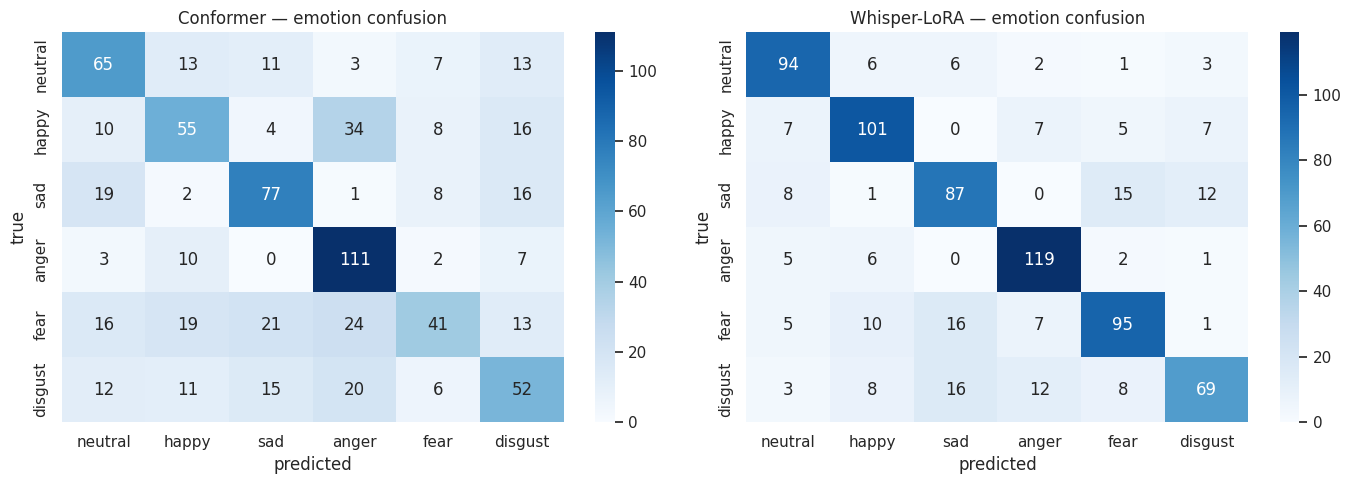


— Conformer per-class —
              precision    recall  f1-score   support

     neutral       0.52      0.58      0.55       112
       happy       0.50      0.43      0.46       127
         sad       0.60      0.63      0.61       123
       anger       0.58      0.83      0.68       133
        fear       0.57      0.31      0.40       134
     disgust       0.44      0.45      0.45       116

    accuracy                           0.54       745
   macro avg       0.54      0.54      0.53       745
weighted avg       0.54      0.54      0.53       745


— Whisper-LoRA per-class —
              precision    recall  f1-score   support

     neutral       0.77      0.84      0.80       112
       happy       0.77      0.80      0.78       127
         sad       0.70      0.71      0.70       123
       anger       0.81      0.89      0.85       133
        fear       0.75      0.71      0.73       134
     disgust       0.74      0.59      0.66       116

    accuracy            

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns, matplotlib.pyplot as plt

def model_size_mb(model):
    return sum(p.numel() * p.element_size() for p in model.parameters()) / 1e6

test_ds_c = SpellEngineDataset(manifest, split="test", augment=False)
test_loader_c = DataLoader(test_ds_c, batch_size=16, shuffle=False,
                           num_workers=2, collate_fn=collate_conformer)
test_ds_w = SpellEngineDataset(manifest, split="test", augment=False,
                               use_whisper_features=True,
                               whisper_extractor=whisper_processor.feature_extractor)
test_loader_w = DataLoader(test_ds_w, batch_size=4, shuffle=False,
                           num_workers=2, collate_fn=collate_whisper)

resume_from_checkpoint(conformer, DIRS["ckpts_conf"],
                       path=Path(DIRS["ckpts_conf"]) / "best.pt")
resume_from_checkpoint(whisper_model, DIRS["ckpts_whis"],
                       path=Path(DIRS["ckpts_whis"]) / "best.pt")

print("Evaluating Conformer …")
conf_metrics, conf_dump = evaluate_conformer(conformer.to(DEVICE), test_loader_c, DEVICE)
print("Evaluating Whisper-LoRA …")
whis_metrics, whis_dump = evaluate_whisper(whisper_model.to(DEVICE), test_loader_w, DEVICE)

report = pd.DataFrame({
    "Model":     ["Conformer (scratch)", "Whisper-Small + LoRA"],
    "Params (M)":[sum(p.numel() for p in conformer.parameters())/1e6,
                  sum(p.numel() for p in whisper_model.parameters() if p.requires_grad)/1e6],
    "Size (MB)": [model_size_mb(conformer), model_size_mb(whisper_model)],
    "WER ↓":     [conf_metrics.get("wer", float("nan")), whis_metrics.get("wer", float("nan"))],
    "CER ↓":     [conf_metrics.get("cer", float("nan")), whis_metrics.get("cer", float("nan"))],
    "Emo Acc ↑": [conf_metrics.get("acc", float("nan")), whis_metrics.get("acc", float("nan"))],
    "Emo F1 ↑":  [conf_metrics.get("f1",  float("nan")), whis_metrics.get("f1",  float("nan"))],
}).round(4)

print("\n" + "="*70)
print("FINAL COMPARISON — SpellEngine ASR + SER")
print("="*70)
print(report.to_string(index=False))
report.to_csv(Path(DIRS["logs"]) / "final_report.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, dump) in zip(axes, [("Conformer", conf_dump), ("Whisper-LoRA", whis_dump)]):
    _, _, yt, yp, _ = dump
    if not yt:
        ax.set_visible(False); continue
    cm = confusion_matrix(yt, yp, labels=list(range(len(EMOTIONS))))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax)
    ax.set_title(f"{name} — emotion confusion")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(Path(DIRS["logs"]) / "confusion_matrices.png", dpi=120)
plt.show()

for name, dump in [("Conformer", conf_dump), ("Whisper-LoRA", whis_dump)]:
    _, _, yt, yp, _ = dump
    if yt:
        print(f"\n— {name} per-class —")
        print(classification_report(yt, yp, target_names=EMOTIONS, zero_division=0))


## CELL 10 — Production Export (ONNX INT8)

Conformer → ONNX FP32 → INT8 dynamic quant for low-latency game inference. CPU-only ONNX runtime (`onnxruntime`) is what your game server would actually use, so we benchmark on CPU here.

Whisper-LoRA's adapters are merged + saved as a HuggingFace folder ready for `optimum.onnxruntime`.

All artefacts land in `/kaggle/working/SpellEngine/exports/` — Kaggle saves these between sessions when you click **Save Version**.

In [12]:
import torch.onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

EXPORT_DIR = Path(DIRS["exports"]); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
onnx_fp32 = EXPORT_DIR / "conformer_fp32.onnx"
onnx_int8 = EXPORT_DIR / "conformer_int8.onnx"

class ConformerForExport(nn.Module):
    """Wrap to fix feat_lens to a static-but-functional path for ONNX tracing."""
    def __init__(self, model): super().__init__(); self.m = model.eval()
    def forward(self, feats):
        flens = torch.full((feats.size(0),), feats.size(-1), dtype=torch.long, device=feats.device)
        ctc_logits, emo_logits, _ = self.m(feats, flens)
        return ctc_logits, emo_logits

export_model = ConformerForExport(conformer).to("cpu").eval()
dummy = torch.randn(1, N_MELS, 400)

# Use the legacy exporter to avoid onnxscript opset mismatches.
torch.onnx.export(
    export_model, dummy, str(onnx_fp32),
    input_names=["features"], output_names=["ctc_logits", "emo_logits"],
    dynamic_axes={"features": {0: "batch", 2: "time"},
                  "ctc_logits": {0: "batch", 1: "time"}, "emo_logits": {0: "batch"}},
    opset_version=18, do_constant_folding=True, dynamo=False)
print(f"✓ FP32 ONNX  → {onnx_fp32}  ({onnx_fp32.stat().st_size/1e6:.1f} MB)")

# Avoid ConvInteger on CPU by restricting dynamic quantization to MatMul/Gemm.
op_types = ["MatMul", "Gemm"]
try:
    quantize_dynamic(str(onnx_fp32), str(onnx_int8),
                     weight_type=QuantType.QInt8, op_types_to_quantize=op_types,
                     optimize_model=False)
except TypeError:
    quantize_dynamic(str(onnx_fp32), str(onnx_int8),
                     weight_type=QuantType.QInt8, op_types_to_quantize=op_types)
print(f"✓ INT8 ONNX  → {onnx_int8}  ({onnx_int8.stat().st_size/1e6:.1f} MB)")

sess = ort.InferenceSession(str(onnx_int8), providers=["CPUExecutionProvider"])
ort_in = {"features": dummy.numpy()}
ort_ctc, ort_emo = sess.run(None, ort_in)
print(f"  ORT INT8 outputs: ctc={ort_ctc.shape}  emo={ort_emo.shape}")

with torch.no_grad():
    ref_ctc, ref_emo = export_model(dummy)
mae_ctc = np.abs(ref_ctc.numpy() - ort_ctc).mean()
mae_emo = np.abs(ref_emo.numpy() - ort_emo).mean()
print(f"  parity MAE  ctc={mae_ctc:.4f}  emo={mae_emo:.4f}   (<0.1 = quantization safe)")

# Whisper-LoRA → merged HF folder
WHIS_OUT = EXPORT_DIR / "whisper_lora_merged"
print(f"\nMerging LoRA adapters into Whisper-Small …")
merged = whisper_model.whisper.merge_and_unload()
merged.save_pretrained(str(WHIS_OUT))
whisper_processor.save_pretrained(str(WHIS_OUT))
torch.save(whisper_model.emo_head.state_dict(), WHIS_OUT / "emo_head.pt")
print(f"✓ Whisper merged → {WHIS_OUT}")

# Latency micro-benchmark (CPU)
import time
def bench(fn, n=20):
    fn()
    t0 = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t0) * 1000 / n

torch_latency = bench(lambda: export_model(dummy))
onnx_latency  = bench(lambda: sess.run(None, ort_in))
print(f"\nLatency (CPU, batch=1, T=400):")
print(f"  PyTorch FP32 : {torch_latency:6.1f} ms")
print(f"  ONNX INT8    : {onnx_latency:6.1f} ms     (speedup ×{torch_latency/onnx_latency:.2f})")

print("\n" + "="*70)
print(" 🪄  SPELLENGINE — TRAINING + EXPORT COMPLETE")
print("="*70)
print(f" Working root       : {PROJECT_ROOT}")
print(f" Conformer ckpts    : {DIRS['ckpts_conf']}")
print(f" Whisper-LoRA ckpts : {DIRS['ckpts_whis']}")
print(f" Production exports : {DIRS['exports']}")
print(f" Logs / report      : {DIRS['logs']}")
print("\n→ Click **Save Version** in the top-right to persist all artefacts!")


✓ FP32 ONNX  → /kaggle/working/SpellEngine/exports/conformer_fp32.onnx  (20.5 MB)
✓ INT8 ONNX  → /kaggle/working/SpellEngine/exports/conformer_int8.onnx  (9.4 MB)
  ORT INT8 outputs: ctc=(1, 100, 29)  emo=(1, 6)
  parity MAE  ctc=0.0319  emo=0.0300   (<0.1 = quantization safe)

Merging LoRA adapters into Whisper-Small …


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Whisper merged → /kaggle/working/SpellEngine/exports/whisper_lora_merged

Latency (CPU, batch=1, T=400):
  PyTorch FP32 :   38.5 ms
  ONNX INT8    :   19.3 ms     (speedup ×2.00)

 🪄  SPELLENGINE — TRAINING + EXPORT COMPLETE
 Working root       : /kaggle/working/SpellEngine
 Conformer ckpts    : /kaggle/working/SpellEngine/checkpoints/conformer
 Whisper-LoRA ckpts : /kaggle/working/SpellEngine/checkpoints/whisper_lora
 Production exports : /kaggle/working/SpellEngine/exports
 Logs / report      : /kaggle/working/SpellEngine/logs

→ Click **Save Version** in the top-right to persist all artefacts!
